# WildSpeech M8.4 — Phase 0: Trusted Evaluation & Reference Parity

**MISSION:** freeze the official-data evaluation, reproduce DrivenData's 14-feature RidgeCV reference (R²≈0.193 mean of 50 folds), establish the run ledger, and test the historical M8.3 models on exactly matching folds **without inventing results**.

**No audio extraction or GPU work is needed.** This notebook mounts Google Drive first, clones the GitHub package, validates official CSVs, creates 50 reference RepeatedKFold splits and 50 school-disjoint robustness splits, runs all 100 reference fits, verifies held-out predictions, and produces a rigorously checked submission CSV under a private Drive output directory. The notebook does **not** submit to the leaderboard.

Research protocol: primary metric = 10-repeat mean pooled OOF R²; published-reference parity metric = mean of 50 fold R² values. Every future comparison must share the frozen fold hash and be preregistered before model fitting. No training on test rows, no test-derived fitted transforms, and no test pseudo-labeling.

Reference: https://blog.drivendata.org/blog/literacy-speech-modeling-reference

## 0. Mount Drive **before** touching competition data

In Colab click Run all, authorize Drive, and confirm the dataset is in MyDrive/WildSpeech. Locally, set WILDSPEECH_DRIVE_ROOT to your mounted folder.

In [1]:
import os, sys, json, subprocess, importlib, warnings, time
from pathlib import Path
from IPython.display import display, Markdown
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    DRIVE=Path("/content/drive/MyDrive")
else:
    DRIVE=Path(os.environ.get("WILDSPEECH_DRIVE_ROOT",str(Path.home()/"MyDrive"))).expanduser()
assert DRIVE.is_dir(), f"Drive not mounted at {DRIVE}"
print("✓ Google Drive:",DRIVE)
print("WildSpeech folders:",[p.name for p in DRIVE.iterdir() if p.is_dir() and "wild" in p.name.lower()])

Mounted at /content/drive
✓ Google Drive: /content/drive/MyDrive
WildSpeech folders: ['WildSpeech', 'WildSpeech_V53', 'WildSpeech_V54_DYNAMICS', 'WildSpeech_V541_SIGNAL_RECOVERY', 'WildSpeech_V542_RESPONSE_EFFORT', 'WildSpeech_V6_MULTIMODAL', 'WildSpeech_M7_DEEP_EDA', 'WildSpeech_M71_PHENOTYPE_BOOSTING', 'WildSpeech_M73_ADAPTIVE_STUDENT_GROUPS', 'WildSpeech_M8']


## 1. Install the exact GitHub source

Installs the local M8/M8.4 package. No ZIP upload. A dirty existing checkout cannot be force-reset; only a fast-forward update is allowed.

In [2]:
URL="https://github.com/mybenkhadda/WildSpeech.git"
CHECKOUT=Path("/content/WildSpeech_git") if IN_COLAB else Path.cwd()/"WildSpeech_git"
PKG=CHECKOUT/"WildSpeech_M8"
if not (CHECKOUT/".git").is_dir():
    if CHECKOUT.exists(): raise RuntimeError(f"Non-Git checkout exists at {CHECKOUT}")
    subprocess.run(["git","clone","--depth","1","--branch","main",URL,str(CHECKOUT)],check=True)
else:
    subprocess.run(["git","-C",str(CHECKOUT),"pull","--ff-only","origin","main"],check=True)
subprocess.run([sys.executable,"-m","pip","install","-q","-e",str(PKG)],check=True)
SOURCE=str(PKG/"src")
if SOURCE not in sys.path:sys.path.insert(0,SOURCE)
GIT_SHA=subprocess.check_output(["git","-C",str(CHECKOUT),"rev-parse","HEAD"],text=True).strip()
from wildspeech_m84.data import locate_data_root,load_official
from wildspeech_m84.folds import build_folds,freeze_folds,validate_folds
from wildspeech_m84.reference import reference_frames,REFERENCE_COLUMNS
from wildspeech_m84.runner import run_phase0
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("✓ Package installed at commit:",GIT_SHA)

✓ Package installed at commit: 589c9cfecfea4ba6b94e29a0254257911d617f5d


## 2. One configuration cell: official files and private output paths

Leave overrides blank when your Drive uses the existing WildSpeech layout. Historial M8.3 research can optionally run, but **cannot be promoted** until its old feature-generation test-dependence is audited. M7.3's original implementation is absent from repository main.

In [3]:
DATA_ROOT_OVERRIDE=""                    # autodiscover six official CSVs
OUTPUT_ROOT_OVERRIDE=""                  # defaults to MyDrive/WildSpeech_M84/phase0
M8_ROOT_OVERRIDE=""                      # defaults to MyDrive/WildSpeech_M8
M7_PROFILE_OVERRIDE=""                   # optional prior M7 profile path
RUN_LEGACY_RESEARCH_ONLY=False           # separate research check; default OFF
REQUIRE_REFERENCE_PARITY=True            # hard stop if mean fold R² outside [0.188,0.198]
ROOT=Path(OUTPUT_ROOT_OVERRIDE).expanduser() if OUTPUT_ROOT_OVERRIDE else DRIVE/"WildSpeech_M84"/"phase0"
ROOT.mkdir(parents=True,exist_ok=True)
print("Phase 0 private output root:",ROOT)
print("Reference acceptance range:",(0.188,0.198))

Phase 0 private output root: /content/drive/MyDrive/WildSpeech_M84/phase0
Reference acceptance range: (0.188, 0.198)


## 3. Data and reference feature preflight — no training

Check six official CSVs, student and label alignment, reference-compatible metadata row order, and the 14 exact reference columns. Train and test student IDs must be disjoint.

In [4]:
DATA_ROOT=locate_data_root(DRIVE,DATA_ROOT_OVERRIDE)
D=load_official(DATA_ROOT,ROOT)
X_REF,X_TEST_REF,Y=reference_frames(D)
assert X_REF.shape==(len(Y),14) and X_TEST_REF.shape==(len(D.test_students),14)
assert X_REF.index.tolist()==D.train_students.index.tolist()
assert X_TEST_REF.index.tolist()==D.submission_format.index.tolist()
print("Train/test:",X_REF.shape,X_TEST_REF.shape,
      "| Train clips:",len(D.train_clips),"| Test clips:",len(D.test_clips))
print("Reference columns:",list(X_REF.columns))
print("Labels order equal to metadata order:",D.order_manifest["labels_original_order_equal"])
print("Canonical student order hash:",D.order_manifest["canonical_student_order_sha256"][:18])
display(X_REF.notna().mean().rename("train_feature_coverage").to_frame().T)
print("Reference data read WITHOUT fitting on test students.")

Train/test: (541, 14) (361, 14) | Train clips: 14704 | Test clips: 9814
Reference columns: ['blending_theta', 'deletion_theta', 'sentence_repetition_theta', 'blending_pct_correct', 'deletion_pct_correct', 'sentence_repetition_pct_correct', 'blending_n_clips', 'deletion_n_clips', 'sentence_repetition_n_clips', 'blending_mean_duration', 'deletion_mean_duration', 'sentence_repetition_mean_duration', 'is_wj4', 'is_11khz']
Labels order equal to metadata order: True
Canonical student order hash: 1c6e7bd0a390d78ab3


,blending_theta,deletion_theta,sentence_repetition_theta,blending_pct_correct,deletion_pct_correct,sentence_repetition_pct_correct,blending_n_clips,deletion_n_clips,sentence_repetition_n_clips,blending_mean_duration,deletion_mean_duration,sentence_repetition_mean_duration,is_wj4,is_11khz
train_feature_coverage,0.939002,0.609982,0.950092,0.959335,0.617375,0.951941,1.0,1.0,1.0,0.963031,0.617375,0.951941,1.0,1.0


Reference data read WITHOUT fitting on test students.


## 4. Freeze 100 folds and verify the split contract

**Student CV:** 5 folds × 10 repeats of RepeatedKFold(seed=42), ordered identically to the reference's metadata frame.

**School robustness:** 5 school-disjoint folds × 10 seeded repetitions, with balanced group assignments. School IDs are split labels, not model features.

In [5]:
FOLDS=build_folds(D.ids,D.groups)
assert validate_folds(FOLDS,D.ids,D.groups)
FOLD_HASH=freeze_folds(FOLDS,D.ids,D.groups,ROOT)
display(FOLDS.groupby("scheme")[["n_train","n_valid"]].agg(["min","mean","max"]).round(1))
print("Frozen fold hash:",FOLD_HASH)
print("Fold file:",ROOT/"folds"/"folds.parquet")
print("Manifest:",ROOT/"manifests"/"fold_manifest.json")

n_train             n_valid            
            min   mean  max     min   mean  max
scheme                                         
school      388  432.8  450      91  108.2  153
student     432  432.8  433     108  108.2  109

Frozen fold hash: 6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949ac6f1e6a16e092c9ce1
Fold file: /content/drive/MyDrive/WildSpeech_M84/phase0/folds/folds.parquet
Manifest: /content/drive/MyDrive/WildSpeech_M84/phase0/manifests/fold_manifest.json


## 5. Read and freeze the preregistered experiment plan

This is recorded **before** model training, in an append-only ledger. Historical models that cannot be faithfully reproduced remain NOT_REPRODUCED; the notebook will not invent past scores.

In [6]:
from wildspeech_m84.ledger import preregister,Ledger
P=preregister(ROOT)
print("Plan hash:",P["plan_hash"])
display(pd.DataFrame(P["comparisons"]))
print("Ledger:",ROOT/"ledger"/"events.jsonl")

Plan hash: ae3ff0f1795c4c206f7e7aef4e3cb2855fb6b13c9ee33aaa4cb3328bbfbaae3d


,comparison_id,baseline,challenger,scope
0,PARITY_REF,None,REF_RIDGE14,"reference parity [0.188,0.198]"
1,M73_VS_REF,REF_RIDGE14,M73_GLOBAL,historical adapter missing until repository so...
2,M83_ALL_VS_REF,REF_RIDGE14,M83_ALL,"exploratory legacy feature-bank parity, not pr..."
3,M83_NO_AUDIO_VS_REF,REF_RIDGE14,M83_WITHOUT_AUDIO_NAMING,legacy taxonomy impure; exploratory-only
4,M83_ALL_VS_NO_AUDIO,M83_WITHOUT_AUDIO_NAMING,M83_ALL,"diagnostic of legacy naming, not causal audio ..."


Ledger: /content/drive/MyDrive/WildSpeech_M84/phase0/ledger/events.jsonl


## 6. Execute the complete Phase 0 reproducible pipeline

This performs all 100 reference folds, saves each fold checkpoint, verifies OOF completeness, computes both R² estimands, writes the 14-feature registry, tests independent singleton test inference, fits the full reference on training rows only, and generates the **submission file** if parity passes. Cached runs can be safely resumed/reused by immutable hashes.

The code never claims an online leaderboard result.

In [7]:
started=time.perf_counter()
RESULT=run_phase0(
    drive_root=DRIVE,
    data_root_override=DATA_ROOT_OVERRIDE,
    output_root_override=OUTPUT_ROOT_OVERRIDE,
    m8_root_override=M8_ROOT_OVERRIDE,
    m7_profile_override=M7_PROFILE_OVERRIDE,
    run_legacy_research=RUN_LEGACY_RESEARCH_ONLY,
    repository_root=CHECKOUT,
    require_parity=REQUIRE_REFERENCE_PARITY,
)
print("Phase 0 execution or verified cache reuse completed in",round(time.perf_counter()-started,1),"seconds")
print("Reference parity:",RESULT["parity_pass"],"| Gate:",RESULT["phase0_gate"])
display(Markdown((ROOT/"parity"/"M84_BASELINE_PARITY.md").read_text()))

[M84] Official data: /content/drive/MyDrive/WildSpeech
[M84] Private output root: /content/drive/MyDrive/WildSpeech_M84/phase0


REF_RIDGE14 locked CV:   0%|          | 0/100 [00:00<?, ?fold/s]

[M84] Mean 50-fold R²: 0.193227
[M84] Phase 0 gate: CONDITIONAL_GO
[M84] Report: /content/drive/MyDrive/WildSpeech_M84/phase0/parity/M84_BASELINE_PARITY.md
Phase 0 execution or verified cache reuse completed in 15.6 seconds
Reference parity: True | Gate: CONDITIONAL_GO


# M8.4 — Phase 0 Baseline Parity and Frozen Evaluation

## Evidence status

**Official training-data run:** PASSED parity
**No official online submission has been made by this pipeline.**

## 1. Reproducibility

- Reference canonical order: metadata row order; labels-order-equal = True
- Canonical student order SHA-256: 1c6e7bd0a390d78ab38b35922302e73327feb7c29abdb1e0deddf4702138778b
- Frozen fold SHA-256: 6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949ac6f1e6a16e092c9ce1
- Official input manifest SHA-256: c38b9d7c5fdfa3285e01368cf0cfbd42d12a8158a6b116b01aaf43790abe8c60
- Reference feature matrix SHA-256: ab8db1878057d191dec45787e2daad61bf3a5ef81eba05962e89c4c984a98f2b
- Code SHA: 589c9cfecfea4ba6b94e29a0254257911d617f5d

## 2. Exact DrivenData 14-feature reference

| Metric | Official-data result | Reference benchmark |
| --- | ---: | ---: |
| Mean 50-fold R² | 0.193227 | 0.193 ±0.005 parity range |
| 50-fold R² SD | 0.043107 | 0.043 reference fold SD |
| Mean 10-repeat pooled OOF R² | 0.199113 | separately reported |
| School-disjoint pooled OOF R² | 0.147363 | robustness only |
| Mean fold MAE | 7.370510 | secondary |
| Mean fold RMSE | 9.915006 | secondary |

**Parity check: PASS**. Reference parity targets mean-fold R² in [0.188, 0.198].
The public leaderboard 0.2888 is an external historical result, NOT a gate or new submission score.

## 3. Model run inventory

| Model | Status | Run ID |
| --- | --- | --- |
| M73_GLOBAL | NOT_REPRODUCED: exact M7.3 implementation absent from repository main | — |
| M83_ALL | RESEARCH_ONLY: M8.3 legacy feature assembly/taxonomy requires compliance audit | — |
| M83_WITHOUT_AUDIO_NAMING | RESEARCH_ONLY: audio-name family also contains correctness variables | — |

## 4. Preregistered paired comparisons

Only compare results from identical frozen folds. Legacy diagnostics are NOT promotion eligible until their train-only feature formation is audited.

No clean historical comparison completed. No missing score has been invented.

## 5. Feature provenance
- Reference features: 14 (exactly 14).
- Registry: {'n_total': 14, 'n_duplicates': 0, 'n_audio': 0, 'n_audio_child_verified': 0, 'n_prohibited': 0, 'family_counts': {'reference_metadata': 8, 'screening_correctness': 6}}
- Test coverage is audit-only; it never determines training transforms or model selection.
- M83 legacy taxonomy incorrectly calls correctness-derived features audio.

## 6. Submission readiness
- Submission file: /content/drive/MyDrive/WildSpeech_M84/phase0/submissions/reference_submission.csv
- SHA-256: 189e50c6bb075aecd62d78434f3ce3922dcfc6e9073948fa11140843c87050e7
- Singleton/batch invariance: True
- Upload to the competition must be performed separately and the actual receipt recorded.

## 7. Decision and Phase 1 handoff

**CONDITIONAL GO**: Exact reference parity and submission invariance passed; unavailable/legacy-only models remain explicitly unresolved.

Pre-register Phase 1 model candidates P1-A (reference with regularized model stack), P1-B (S2–S5 screening bundle), P1-C (leave-one-block-out ablations).
Do not use outer folds to tune blend weights or feature-building decisions.

## 8. Limits
- This harness does not infer actual leaderboard scores.
- Nadeau–Bengio corrected t is approximate and does not correct selection over many trials.
- The school-disjoint scheme is robustness only, not the leaderboard split.
- Instrument subgroup R² is undefined for constant-target or small subsets.
- Restored M7.3 source and independently audited M8.3 transformation code are prerequisites for true historical parity.


## 7. Reference R² results: mean of folds and pooled OOF

Published reference comparison requires *mean of 50 fold R²*; the primary competition-oriented summary uses *10-repeat mean pooled OOF R²*. Do not conflate these estimands.

In [9]:
from wildspeech_m84.metrics import summarize_oof
import pandas as pd

# Reuse the completed reference run
RUN_DIR = ROOT / "runs" / RESULT["reference_run_id"]

oof = pd.read_parquet(
    RUN_DIR / "oof_predictions_PRIVATE.parquet"
)

_, _, instrument_metrics = summarize_oof(
    oof,
    FOLDS,
    D.ids,
    Y,
    instruments=D.instruments,
)

assert not instrument_metrics.empty

path = RUN_DIR / "instrument_metrics.parquet"
instrument_metrics.to_parquet(path, index=False)

print("Fixed:", path)
display(instrument_metrics.groupby(
    ["scheme", "instrument"]
)[["r2", "n", "sse"]].mean())

Fixed: /content/drive/MyDrive/WildSpeech_M84/phase0/runs/ref_ridge14__5e9a4b9127389e/instrument_metrics.parquet


r2      n           sse
scheme  instrument                               
school  ktea3       0.115596  279.0  35984.125869
        wj4         0.183882  262.0  21115.343899
student ktea3       0.192147  279.0  32869.456132
        wj4         0.197446  262.0  20764.390849

In [10]:
reference_id=RESULT["reference_run_id"]
RUN_DIR=ROOT/"runs"/reference_id
FOLD_METRICS=pd.read_parquet(RUN_DIR/"fold_metrics.parquet")
POOLED=pd.read_parquet(RUN_DIR/"pooled_metrics.parquet")
INSTRUMENT=pd.read_parquet(RUN_DIR/"instrument_metrics.parquet")
OOF=pd.read_parquet(RUN_DIR/"oof_predictions_PRIVATE.parquet")
print("Reference mean fold R²:",FOLD_METRICS[FOLD_METRICS.scheme=="student"].r2.mean())
print("Reference mean pooled OOF R²:",POOLED[POOLED.scheme=="student"].r2.mean())
print("School-disjoint mean pooled OOF R²:",POOLED[POOLED.scheme=="school"].r2.mean())
display(POOLED.groupby("scheme")[["r2","mae","rmse"]].agg(["mean","std"]).round(5))
print("Private OOF:",RUN_DIR/"oof_predictions_PRIVATE.parquet")

Reference mean fold R²: 0.1932274944147675
Reference mean pooled OOF R²: 0.19911336872653493
School-disjoint mean pooled OOF R²: 0.14736300743344016


r2               mae               rmse         
            mean      std     mean      std      mean      std
scheme                                                        
school   0.14736  0.01632  7.67501  0.08605  10.27305  0.09804
student  0.19911  0.00706  7.37051  0.04123   9.95674  0.04381

Private OOF: /content/drive/MyDrive/WildSpeech_M84/phase0/runs/ref_ridge14__5e9a4b9127389e/oof_predictions_PRIVATE.parquet


## 8. Figure: 50 locked-fold R² scores and between-repeat variability

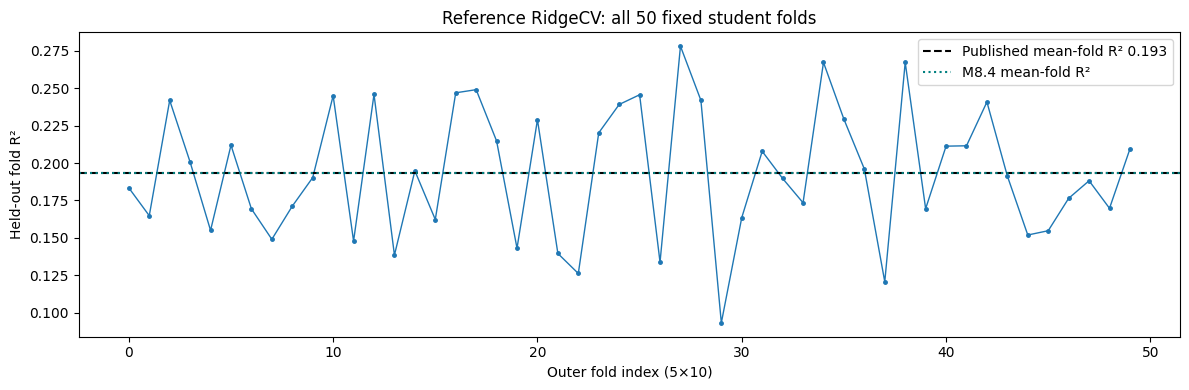

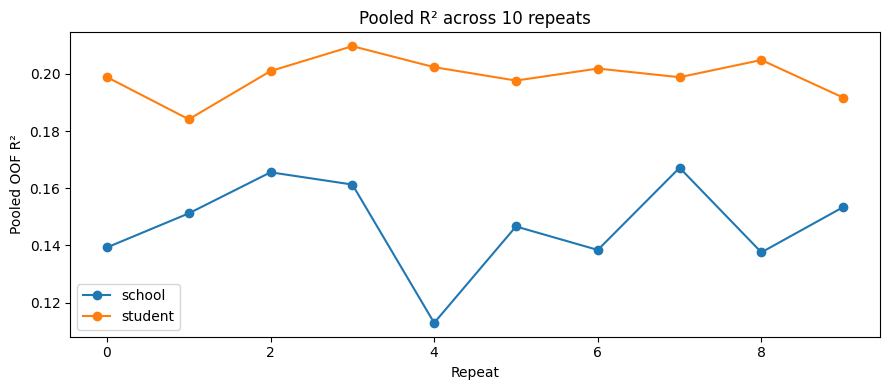

In [11]:
FIGS=ROOT/"figures";FIGS.mkdir(exist_ok=True,parents=True)
f=FOLD_METRICS[FOLD_METRICS.scheme=="student"].sort_values(["repeat","fold"])
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(range(len(f)),f.r2,".-",ms=5,lw=1)
ax.axhline(.193,color="black",ls="--",label="Published mean-fold R² 0.193")
ax.axhline(f.r2.mean(),color="teal",ls=":",label="M8.4 mean-fold R²")
ax.set(xlabel="Outer fold index (5×10)",ylabel="Held-out fold R²",
       title="Reference RidgeCV: all 50 fixed student folds")
ax.legend();fig.tight_layout()
fig.savefig(FIGS/"01_reference_50fold_r2.png",dpi=170);plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(9,4))
for label,g in POOLED.groupby("scheme"):
    ax.plot(g.repeat,g.r2,"o-",label=label)
ax.set(xlabel="Repeat",ylabel="Pooled OOF R²",title="Pooled R² across 10 repeats")
ax.legend();fig.tight_layout()
fig.savefig(FIGS/"02_pooled_r2_repeats.png",dpi=170);plt.show();plt.close(fig)

## 9. Figure: instrument-specific generalization

Only report a subgroup R² when it has adequate training-sample support and nonzero target variance. These are **held-out training outcomes**, not hidden-test labels.

r2      n         sse
scheme  instrument                           
school  ktea3       0.1156  279.0  35984.1259
        wj4         0.1839  262.0  21115.3439
student ktea3       0.1921  279.0  32869.4561
        wj4         0.1974  262.0  20764.3908

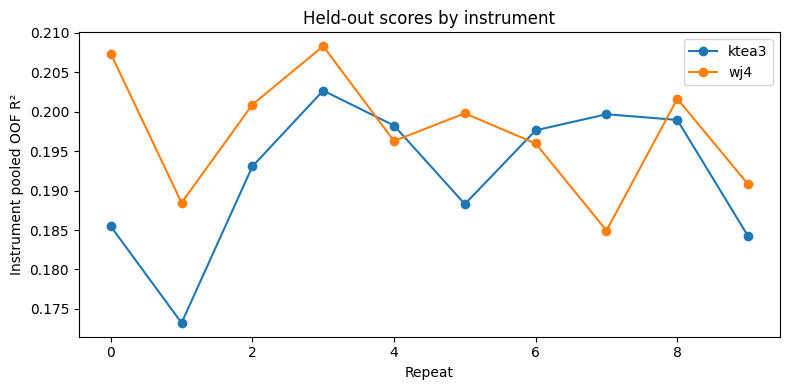

In [12]:
display(INSTRUMENT.groupby(["scheme","instrument"])[["r2","n","sse"]].mean().round(4))
instrument_student=INSTRUMENT[INSTRUMENT.scheme=="student"]
fig,ax=plt.subplots(figsize=(8,4))
for name,g in instrument_student.groupby("instrument"):
    ax.plot(g.repeat,g.r2,marker="o",label=name)
ax.set(xlabel="Repeat",ylabel="Instrument pooled OOF R²",
       title="Held-out scores by instrument")
ax.legend();fig.tight_layout()
fig.savefig(FIGS/"03_instrument_robustness.png",dpi=170);plt.show();plt.close(fig)

## 10. OOF calibration and target error atlas

Use one prediction per student (repeat 0), not all repeated OOF predictions as independent records.

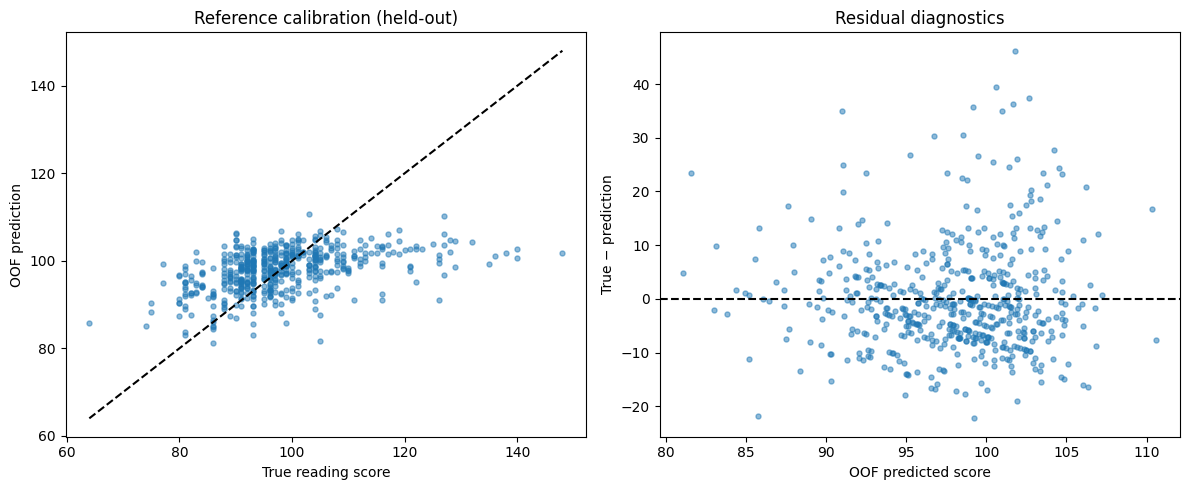

In [13]:
d=OOF[(OOF.scheme=="student")&(OOF.repeat==0)].sort_values("pos")
assert len(d)==len(Y)
fig,axs=plt.subplots(1,2,figsize=(12,5))
axs[0].scatter(d.y_true,d.y_pred,s=13,alpha=.5)
lo=min(d.y_true.min(),d.y_pred.min());hi=max(d.y_true.max(),d.y_pred.max())
axs[0].plot([lo,hi],[lo,hi],"k--")
axs[0].set(xlabel="True reading score",ylabel="OOF prediction",
           title="Reference calibration (held-out)")
axs[1].scatter(d.y_pred,d.y_true-d.y_pred,s=13,alpha=.5)
axs[1].axhline(0,color="black",ls="--")
axs[1].set(xlabel="OOF predicted score",ylabel="True − prediction",
           title="Residual diagnostics")
fig.tight_layout();fig.savefig(FIGS/"04_calibration_residuals.png",dpi=170);plt.show();plt.close(fig)

## 11. Audit provenance registry

A model feature can be reference-protocol metadata **and** an acoustic nuisance proxy simultaneously. The registry records separate source and modeling roles. Test coverage is audit-only and never determines fitted parameters.

In [14]:
REGISTRY=pd.read_csv(ROOT/"features"/"registry.csv")
display(REGISTRY[["feature_name","family","source_file","uses_item_score","uses_audio",
                  "nuisance","is_duplicate","train_coverage","test_coverage_audit_only"]])
assert len(REGISTRY)==14
assert not REGISTRY.allowed_in_speech_arm.fillna(False).any()
print("Feature names match official reference exactly:",REGISTRY.feature_name.tolist()==REFERENCE_COLUMNS)

,feature_name,family,source_file,uses_item_score,uses_audio,nuisance,is_duplicate,train_coverage,test_coverage_audit_only
0,blending_theta,screening_correctness,official_metadata,False,False,False,False,0.939002,0.947368
1,deletion_theta,screening_correctness,official_metadata,False,False,False,False,0.609982,0.590028
2,sentence_repetition_theta,screening_correctness,official_metadata,False,False,False,False,0.950092,0.939058
3,blending_pct_correct,screening_correctness,official_metadata,True,False,False,False,0.959335,0.958449
4,deletion_pct_correct,screening_correctness,official_metadata,True,False,False,False,0.617375,0.595568
5,sentence_repetition_pct_correct,screening_correctness,official_metadata,True,False,False,False,0.951941,0.950139
6,blending_n_clips,reference_metadata,official_metadata,False,False,False,False,1.000000,1.000000
7,deletion_n_clips,reference_metadata,official_metadata,False,False,False,False,1.000000,1.000000
8,sentence_repetition_n_clips,reference_metadata,official_metadata,False,False,False,False,1.000000,1.000000
9,blending_mean_duration,reference_metadata,official_metadata,False,False,True,False,0.963031,0.961219


Feature names match official reference exactly: True


## 12. Validate submission artifact independently

A candidate CSV is generated only after exact reference parity passes. Check row count/order, absence of NaNs, SHA-256, and proof that one student's prediction does not depend on other test rows. This cell does **not** upload anything to the competition.

In [15]:
from wildspeech_m84.data import digest_bytes
if RESULT["parity_pass"]:
    sub=ROOT/"submissions"/"reference_submission.csv"
    frame=pd.read_csv(sub,dtype={"subject_id":str})
    assert list(frame)==["subject_id","outcome_score"]
    assert frame.subject_id.tolist()==D.submission_format.index.tolist()
    assert frame.outcome_score.notna().all()
    assert np.isfinite(frame.outcome_score.to_numpy()).all()
    assert digest_bytes(sub)==(ROOT/"submissions"/"reference_submission.sha256").read_text().strip()
    print("Submission ready (NOT submitted):",sub)
    print("SHA-256:",digest_bytes(sub))
else:
    print("NO-GO: reference parity not yet reproduced; do NOT submit.")

Submission ready (NOT submitted): /content/drive/MyDrive/WildSpeech_M84/phase0/submissions/reference_submission.csv
SHA-256: 189e50c6bb075aecd62d78434f3ce3922dcfc6e9073948fa11140843c87050e7


## 13. Historical-model parity is separate, never silently substituted

M7.3's original global source is not in GitHub main, so it is marked NOT_REPRODUCED. Optional M8.3 reruns use the fixed folds for research, but the legacy feature bank must pass a fresh train-only preprocessing audit before entering the official promotion gate. Never interpret the historical without_audio family as genuinely speech-free.

In [16]:
print("Historical status:")
display(pd.DataFrame([{"model":k,"status":v} for k,v in RESULT["historical_status"].items()]))
if RESULT["comparisons"]:
    display(pd.DataFrame(RESULT["comparisons"])[
        ["baseline","challenger","mean_fold_delta_r2","corrected_t",
         "win_fraction","school_pooled_delta_r2","gate"]])
else:
    print("No invented old R² scores. Set RUN_LEGACY_RESEARCH_ONLY=True only for labeled diagnostics.")

Historical status:


,model,status
0,M73_GLOBAL,NOT_REPRODUCED: exact M7.3 implementation abse...
1,M83_ALL,RESEARCH_ONLY: M8.3 legacy feature assembly/ta...
2,M83_WITHOUT_AUDIO_NAMING,RESEARCH_ONLY: audio-name family also contains...


No invented old R² scores. Set RUN_LEGACY_RESEARCH_ONLY=True only for labeled diagnostics.


## 14. Experiment ledger and invariants

Every run must record the Git SHA, feature hash, fold hash, status, predictions path and metrics. Outputs with mismatched hashes must never enter paired model comparisons.

In [17]:
ledger=pd.read_parquet(ROOT/"ledger"/"experiments.parquet")
cols=[c for c in ["run_id","model_id","status","git_sha","feature_set_hash","fold_hash",
                  "mean_fold_r2","mean_pooled_oof_r2","oof_path"] if c in ledger]
display(ledger[cols])
assert (ledger[ledger.model_id=="REF_RIDGE14"].status=="COMPLETE").all()
assert (ledger[ledger.model_id=="REF_RIDGE14"].fold_hash==FOLD_HASH).all()
print("Ledger events:",ROOT/"ledger"/"events.jsonl")

,run_id,model_id,status,git_sha,feature_set_hash,fold_hash,mean_fold_r2,mean_pooled_oof_r2,oof_path
0,ref_ridge14__5e9a4b9127389e,REF_RIDGE14,COMPLETE,589c9cfecfea4ba6b94e29a0254257911d617f5d,ab8db1878057d191dec45787e2daad61bf3a5ef81eba05...,6ee0f59c8cf5ea3d8f20f5fd500353419587660e00949a...,0.193227,0.199113,/content/drive/MyDrive/WildSpeech_M84/phase0/r...
1,M73_GLOBAL_UNAVAILABLE,M73_GLOBAL,NOT_REPRODUCED,None,None,None,NaN,NaN,None
2,M83_LEGACY_NOT_AUDITED,M83_LEGACY,NOT_REPRODUCED,None,None,None,NaN,NaN,None


Ledger events: /content/drive/MyDrive/WildSpeech_M84/phase0/ledger/events.jsonl


## 15. Phase 0 gate, Phase 1 handoff and competition submission

**GO criteria:** exact reference mean-of-fold R² in [0.188,0.198], immutable 100 folds, complete and reproducible OOF, 14/14 known feature lineage, independent test inference, strict CSV schema and checksum.

**CONDITIONAL GO:** reference passes but exact historical adapter unavailable; start Phase 1 against the frozen reference only. **NO GO:** baseline mismatch, any fold leakage, test-row fitting, failed inference invariance or changing fold hash.

**Next M0+ predeclared experiments:** (A) stronger regularized reference stack; (B) bundled S2–S5 item-level, theta splines, instrument interactions and missing task signals; (C) block-by-block ablations. All item difficulty statistics must be learned inside training folds.

If approved for an external leaderboard check: upload only the validated CSV and record the *actual* receipt and public score. **Do not tune to the public leaderboard.**